# P08: cheap improvements of the ResNet

ADR 0011 decided one time-boxed round of cheap improvements. The frozen ResNet-18 scores 80.3% on validation (5 seeds); it has 93%
train accuracy against about 80% on validation, so the limit is generalisation, not capacity. Everything here keeps the network
**frozen**: the images are passed through it once and the result is kept, so each experiment takes minutes.

| experiment | what changes | why it might help |
|---|---|---|
| `resnet18_multi` | the final layer sees the pooled outputs of the **three last blocks** (896 numbers) instead of the last one (512) | genres depend on texture, which the middle layers hold |
| `resnet18_aug4` | **4 augmented copies** of each training image (random crop, mirror, colour), 9,600 training rows instead of 1,920 | the usual remedy for too few images |
| flip averaging | at evaluation time, the prediction averages an image and its mirror image | free, often about 1 point |
| `resnet50_head` | a frozen **ResNet-50** instead of ResNet-18 | better features, but slower to run (about 2 times, see the results) |

**How we judge** (ADR 0011): each experiment uses 5 seeds; a change counts only if its mean beats the reference (80.3%) by clearly more
than the noise, about **2 points**; we look at the smoother measures, not only the best epoch; **the test set (museum B) is not used**
(ADR 0003). If nothing helps clearly, the frozen ResNet-18 remains our reference ResNet.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy.vision.utils import (
    build_resnet_head, evaluate, evaluate_with_flip, fit, load_resnet_data, load_result, run_experiment, summary)

# The frozen ResNet-18 of P06: the reference.
BASE = {
    "model": "resnet18",
    "image_size": 224,
    "dropout": 0.0,
    "batch_size": 64,
    "weight_decay": 0.0,
    "seed": 0,
    "finetune": "head",
    "epochs": 30,
    "lr": 1e-3,
}

MULTI = {**BASE, "features": "multi"}
AUG = {**BASE, "augment": 4, "flip_eval": True}  # flip_eval also prepares the mirrored validation images, for flip averaging
R50 = {**BASE, "model": "resnet50"}

runs_table = summary()


def saved_run(name):
    """The earliest saved run with this name."""
    rows = runs_table[runs_table["name"] == name].sort_values("date")
    return load_result(rows["file"].iloc[0])


reference = saved_run("resnet18_head")

# Safety check: BASE is exactly the config of the reference run, so only the changes above can explain a difference.
assert BASE == reference["config"]

## 1. Features from several layers

The same frozen ResNet-18, but the final layer receives 896 numbers per image (the pooled outputs of layer2, layer3 and layer4)
instead of 512. About a minute for the features, seconds to train.

In [2]:
t0 = time.time()
multi = run_experiment("resnet18_multi", MULTI, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=5)
print(f"total {time.time() - t0:.0f} s, including the frozen features")

4485 parameters | before training: loss 1.716 (ln 5 = 1.609), accuracy 21.2%
epoch   1 | train loss 0.744 acc 0.783 | val loss 0.791 acc 0.742
epoch   5 | train loss 0.434 acc 0.849 | val loss 0.523 acc 0.794
epoch  10 | train loss 0.352 acc 0.881 | val loss 0.498 acc 0.792
epoch  15 | train loss 0.310 acc 0.895 | val loss 0.509 acc 0.802
epoch  20 | train loss 0.270 acc 0.909 | val loss 0.509 acc 0.794
epoch  25 | train loss 0.253 acc 0.922 | val loss 0.524 acc 0.781
epoch  30 | train loss 0.228 acc 0.932 | val loss 0.533 acc 0.794

best validation accuracy 80.4% at epoch 6 (1 s)
seed 1 (1 of 4 more): training, about 1 s...
   best validation accuracy 80.8% at epoch 12
seed 2 (2 of 4 more): training, about 1 s...
   best validation accuracy 80.8% at epoch 8
seed 3 (3 of 4 more): training, about 1 s...
   best validation accuracy 80.8% at epoch 14
seed 4 (4 of 4 more): training, about 1 s...
   best validation accuracy 80.0% at epoch 20
saved results/resnet18_multi_2026-10-22_19-13-29.

## 2. Data augmentation

Each training image gets 4 random variants (crop, mirror, colour jitter), and the network sees the original and its 4 copies. The
features of the copies are computed once, so this takes a few minutes (5 passes over the training images), then seconds to train.
The validation images are never augmented.

In [3]:
t0 = time.time()
aug = run_experiment("resnet18_aug4", AUG, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=5)
print(f"total {time.time() - t0:.0f} s, including the frozen features of the augmented copies")

2565 parameters | before training: loss 1.863 (ln 5 = 1.609), accuracy 11.2%
epoch   1 | train loss 0.516 acc 0.816 | val loss 0.582 acc 0.785
epoch   5 | train loss 0.326 acc 0.889 | val loss 0.509 acc 0.800
epoch  10 | train loss 0.266 acc 0.906 | val loss 0.544 acc 0.785
epoch  15 | train loss 0.236 acc 0.919 | val loss 0.559 acc 0.785
epoch  20 | train loss 0.212 acc 0.927 | val loss 0.593 acc 0.790
epoch  25 | train loss 0.196 acc 0.932 | val loss 0.621 acc 0.781
epoch  30 | train loss 0.185 acc 0.939 | val loss 0.657 acc 0.777

best validation accuracy 81.7% at epoch 4 (4 s)
seed 1 (1 of 4 more): training, about 4 s...
   best validation accuracy 80.8% at epoch 2
seed 2 (2 of 4 more): training, about 4 s...
   best validation accuracy 80.2% at epoch 2
seed 3 (3 of 4 more): training, about 4 s...
   best validation accuracy 80.8% at epoch 5
seed 4 (4 of 4 more): training, about 4 s...
   best validation accuracy 80.6% at epoch 2
saved results/resnet18_aug4_2026-10-22_19-19-20.pkl 

### Flip averaging on top

At evaluation time, each validation image is also given mirrored, and the two predictions are averaged. We retrain the 5 seeds of
the augmented model (seconds, the features are kept in `aug["data"]`) and compare the accuracy with and without averaging.

In [4]:
data = aug["data"]
plain, flipped = [], []
for seed in range(5):
    torch.manual_seed(seed)
    model = build_resnet_head(AUG)
    result = fit(model, data, epochs=AUG["epochs"], lr=AUG["lr"], batch_size=AUG["batch_size"],
                 weight_decay=AUG["weight_decay"], seed=seed, verbose=False)  # the model keeps its best epoch
    plain.append(evaluate(model, data["X_val"], data["y_val"])[1])
    flipped.append(evaluate_with_flip(model, data["X_val"], data["X_val_flip"], data["y_val"]))

for seed, (a, b) in enumerate(zip(plain, flipped)):
    print(f"seed {seed}: {100 * a:.1f}% without, {100 * b:.1f}% with flip averaging ({100 * (b - a):+.1f})")
print(f"\nmean: {100 * np.mean(plain):.1f}% without, {100 * np.mean(flipped):.1f}% with flip averaging "
      f"({100 * (np.mean(flipped) - np.mean(plain)):+.1f} points)")

seed 0: 81.7% without, 81.0% with flip averaging (-0.6)
seed 1: 80.8% without, 80.4% with flip averaging (-0.4)
seed 2: 80.2% without, 80.0% with flip averaging (-0.2)
seed 3: 80.8% without, 81.5% with flip averaging (+0.6)
seed 4: 80.6% without, 81.7% with flip averaging (+1.0)

mean: 80.8% without, 80.9% with flip averaging (+0.1 points)


## 3. A frozen ResNet-50

Same recipe with the bigger pretrained network (2,048 features per image). The ImageNet weights (about 100 MB) are downloaded the
first time. This is the slowest one: expect 2 to 3 minutes for the frozen features.

In [5]:
t0 = time.time()
r50 = run_experiment("resnet50_head", R50, build_model=build_resnet_head, load_fn=load_resnet_data, seeds=5)
print(f"total {time.time() - t0:.0f} s, including the frozen features")

10245 parameters | before training: loss 1.597 (ln 5 = 1.609), accuracy 24.1%
epoch   1 | train loss 0.548 acc 0.825 | val loss 0.604 acc 0.779
epoch   5 | train loss 0.351 acc 0.882 | val loss 0.485 acc 0.808
epoch  10 | train loss 0.281 acc 0.897 | val loss 0.483 acc 0.817
epoch  15 | train loss 0.222 acc 0.927 | val loss 0.500 acc 0.796
epoch  20 | train loss 0.191 acc 0.941 | val loss 0.506 acc 0.798
epoch  25 | train loss 0.165 acc 0.957 | val loss 0.523 acc 0.804
epoch  30 | train loss 0.148 acc 0.963 | val loss 0.540 acc 0.798

best validation accuracy 81.7% at epoch 10 (1 s)
seed 1 (1 of 4 more): training, about 1 s...
   best validation accuracy 82.3% at epoch 5
seed 2 (2 of 4 more): training, about 1 s...
   best validation accuracy 82.3% at epoch 3
seed 3 (3 of 4 more): training, about 1 s...
   best validation accuracy 81.7% at epoch 4
seed 4 (4 of 4 more): training, about 1 s...
   best validation accuracy 81.7% at epoch 18
saved results/resnet50_head_2026-10-22_19-22-14.p

## 4. Combine, only if two changes each helped

If the several-layers features and the augmentation each beat the reference clearly (see section 5), put `COMBINE = True` and run
this cell: both together, with 5 seeds. Leave it at `False` otherwise.

In [6]:
COMBINE = False

if COMBINE:
    combined = run_experiment("resnet18_multi_aug4", {**MULTI, "augment": 4}, build_model=build_resnet_head,
                              load_fn=load_resnet_data, seeds=5)

## 5. The verdict

Mean validation accuracy over 5 seeds (the bar is the standard deviation), against the reference. The shaded band is +/- 2 points:
a change has to leave it, clearly, to count (ADR 0011).

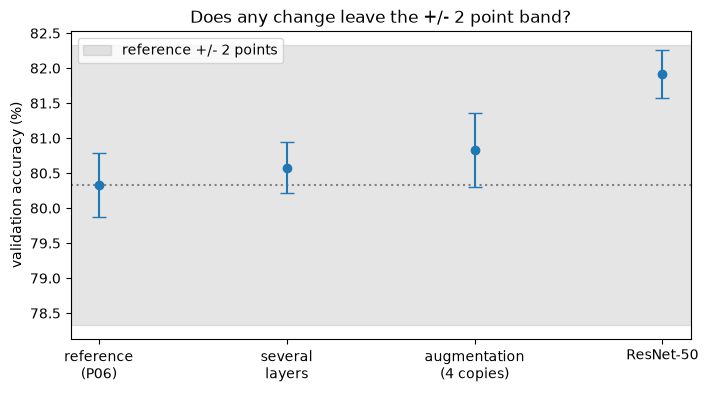

,mean (%),std (points),difference to reference
reference (P06),80.3,0.5,0.0
several layers,80.6,0.4,0.2
augmentation (4 copies),80.8,0.5,0.5
ResNet-50,81.9,0.3,1.6


In [7]:
table = summary()


def score(name):
    """Mean and std (in %) of the best validation accuracy over the 5 seeds of a run."""
    row = table[table["name"] == name].sort_values("date").iloc[0]
    return 100 * row["val_acc_mean"], 100 * row["val_acc_std"]


labels = {"resnet18_head": "reference\n(P06)", "resnet18_multi": "several\nlayers", "resnet18_aug4": "augmentation\n(4 copies)",
          "resnet50_head": "ResNet-50"}
if "resnet18_multi_aug4" in set(table["name"]):
    labels["resnet18_multi_aug4"] = "several layers\n+ augmentation"
scores = {name: score(name) for name in labels}
ref = scores["resnet18_head"][0]

plt.figure(figsize=(8, 4))
plt.axhspan(ref - 2, ref + 2, color="grey", alpha=0.2, label="reference +/- 2 points")
plt.axhline(ref, color="grey", linestyle=":")
plt.errorbar(range(len(scores)), [m for m, s in scores.values()], yerr=[s for m, s in scores.values()], fmt="o", capsize=5)
plt.xticks(range(len(scores)), list(labels.values()))
plt.ylabel("validation accuracy (%)")
plt.title("Does any change leave the +/- 2 point band?")
plt.legend()
plt.show()

pd.DataFrame({labels[n].replace("\n", " "): {"mean (%)": round(m, 1), "std (points)": round(s, 1), "difference to reference": round(m - ref, 1)}
              for n, (m, s) in scores.items()}).T

## 6. Smoother measures, and the cost

The best epoch flatters a model (ADR 0008), so we also look at the last epoch, the mean of the last 10 epochs, and the score at the
epoch of lowest validation loss, for the main seed of each run. `n_params` counts the trainable weights of the final layer.

In [8]:
runs = {"reference (P06)": reference["history"], "several layers": multi["result"]["history"],
        "augmentation": aug["result"]["history"], "ResNet-50": r50["result"]["history"]}


def measures(history):
    val = np.array(history["val_acc"])
    loss = np.array(history["val_loss"])
    return {
        "best epoch (%)": 100 * val.max(),
        "last epoch (%)": 100 * val[-1],
        "mean of last 10 (%)": 100 * val[-10:].mean(),
        "at lowest val loss (%)": 100 * val[loss.argmin()],
        "train acc, last (%)": 100 * history["train_acc"][-1],
        "lowest val loss": loss.min(),
    }


display(pd.DataFrame({label: measures(h) for label, h in runs.items()}).round(1))
summary()[summary()["name"].isin(list(labels))][
    ["name", "model", "features", "augment", "n_params", "best_val_acc", "val_acc_mean", "val_acc_std"]]

,reference (P06),several layers,augmentation,ResNet-50
best epoch (%),80.2,80.4,81.7,81.7
last epoch (%),79.6,79.4,77.7,79.8
mean of last 10 (%),79.1,79.2,78.1,80.0
at lowest val loss (%),79.0,79.6,81.7,80.8
"train acc, last (%)",93.3,93.2,93.9,96.3
lowest val loss,0.5,0.5,0.5,0.5


,name,model,features,augment,n_params,best_val_acc,val_acc_mean,val_acc_std
14,resnet50_head,resnet50,NaN,NaN,10245,0.8167,0.8192,0.0034
13,resnet18_aug4,resnet18,NaN,4.0,2565,0.8167,0.8083,0.0053
12,resnet18_multi,resnet18,multi,NaN,4485,0.8042,0.8058,0.0037
7,resnet18_head,resnet18,NaN,NaN,2565,0.8021,0.8033,0.0046


## 7. By genre

Each genre has only 96 validation images, so one value moves a lot from one run to another.

In [9]:
confusions = {"reference": reference["val_confusion"], "several layers": multi["confusion"],
              "augmentation": aug["confusion"], "ResNet-50": r50["confusion"]}
pd.DataFrame({name: {genre: c.loc[genre, genre] / c.loc[genre].sum() for genre in c.index}
              for name, c in confusions.items()}).round(2)

,reference,several layers,augmentation,ResNet-50
cityscape,0.76,0.81,0.81,0.84
landscape,0.80,0.77,0.79,0.71
portrait,0.80,0.73,0.77,0.80
religious_painting,0.72,0.80,0.76,0.84
still_life,0.93,0.91,0.95,0.89


## No test score here

These are experiments on validation. No model of this notebook is final, so none is scored on museum B (ADR 0003).

## What we see

Validation accuracy, best epoch, mean of 5 seeds (standard deviation in brackets). The reference is the frozen ResNet-18 of P06.

| experiment | trainable weights | validation | difference to reference | time (frozen features included) |
|---|---|---|---|---|
| reference: frozen ResNet-18 | 2,565 | **80.3%** (0.5) | | about 70 s |
| features from several layers | 4,485 | 80.6% (0.4) | +0.3 | 77 s |
| augmentation (4 copies) | 2,565 | 80.8% (0.5) | +0.5 | 351 s |
| augmentation, plus flip averaging | 2,565 | 80.9% | +0.6 | |
| frozen ResNet-50 | 10,245 | **81.9%** (0.3) | +1.6 | 159 s |

- **Nothing left the +/- 2 point band, so nothing counts as an improvement** (ADR 0011). Several layers (+0.3) and augmentation (+0.5)
  are within the noise, and flip averaging adds only +0.1 point on top of augmentation (it helped two seeds and hurt three). The
  combination of the first two was not run, since neither helped.
- **Augmentation is slightly worse on the smoother measures:** last epoch 77.7% and mean of the last 10 epochs 78.1%, against 79.6%
  and 79.1% for the reference. The augmented model peaks and then drifts, so its best epoch (81.7%) flatters it.
- **The frozen ResNet-50 is the only change that looks consistent:** all 5 seeds fall between 81.7% and 82.3%, against 79.8% to 81.0%
  for the reference. But +1.6 points is below our threshold; on 480 validation images it is about 8 images; and it takes about twice
  as long to run as ResNet-18 (159 s against 77 s for the frozen features). Our earlier estimate of "4 times slower" came from a
  first measurement that included warm-up and the weight download; the full runs show about 2 times, in line with the 4.1 against
  1.8 GFLOPs of the two networks.
- **A plateau.** Three different ways of giving the network more information (middle layers, more training images by augmentation,
  a bigger backbone) all end between 80% and 82%. That suggests the limit is now the data and the labels (genres overlap: religious
  painting and portrait, cityscape and landscape), not the network. We have not looked at the errors.

Decision (ADR 0011): the frozen ResNet-18 remains our reference ResNet; the ResNet-50 is a documented option if accuracy matters
more than cost. The final model is chosen later, once the cost per image is measured.